In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('lifecyclesavings.csv')

print("Dataset Shape:", df.shape)

print("\nMissing Values Count:")
print(df.isnull().sum())

print("\nOverall Column Means:")
print(df.mean(numeric_only=True))

Dataset Shape: (50, 6)

Missing Values Count:
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

Overall Column Means:
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


I have a life-cycle savings dataset with 50 rows and features: sr, pop15, pop75, dpi, ddpi. Write Python code using scikit-learn to normalize these features using StandardScaler, perform K-Means clustering with 3 clusters (setting random_state=42), append the cluster labels to the DataFrame, and visualize the clusters using a scatter plot of pop15 vs. dpi with clearly labeled axes.

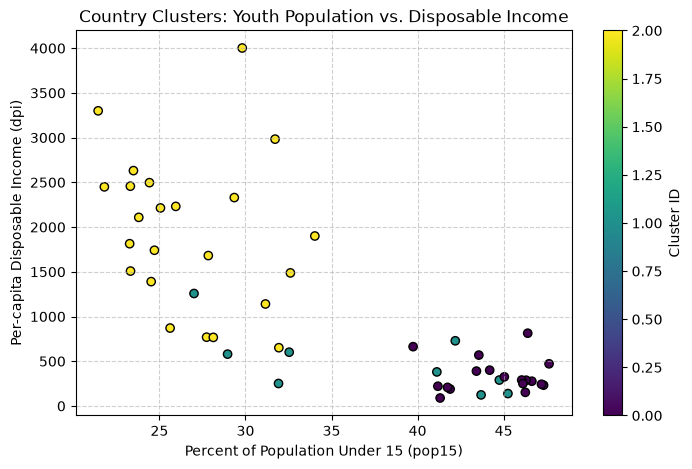

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Define features for clustering
features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']
X = df[features]

# Normalize features 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)

# Visualize the resulting groups
plt.figure(figsize=(8, 5))
scatter = plt.scatter(df['pop15'], df['dpi'], c=df['cluster'], cmap='viridis', edgecolors='k')
plt.title('Country Clusters: Youth Population vs. Disposable Income')
plt.xlabel('Percent of Population Under 15 (pop15)')
plt.ylabel('Per-capita Disposable Income (dpi)')
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [5]:
cluster_summary = df.groupby('cluster')[features].mean()
print("Independently Verified Cluster Means:")
print(cluster_summary)


Independently Verified Cluster Means:
                sr      pop15     pop75          dpi      ddpi
cluster                                                       
0         6.138889  44.556111  1.079444   337.153333  2.359444
1        13.591111  37.492222  1.623333   483.241111  7.662222
2        10.901304  26.740870  3.504783  1953.043043  3.323913


I am working on an analysis of the Life-Cycle Savings dataset (variables: sr [savings rate], pop15 [percent youth], pop75 [percent elderly], dpi [disposable income], ddpi [income growth]).
Based on our K-Means clustering, the data broke down into three distinct macroeconomic profiles:
1. Cluster 0: Characterized by a very high youth population (around 44-45%), very low disposable income, and a lower personal savings rate.
2. Cluster 1: Characterized by an exceptionally high economic growth rate (ddpi) and the highest personal savings rate.
3. Cluster 2: Characterized by a low youth population, an aging demographic profile (highest pop75), and very high disposable income.

The stark differences between the clusters are driven primarily by age-dependency ratios and their direct impact on a nation's economic lifecycles. Countries in Cluster 0 face high youth dependency, where household income is largely diverted toward raising children rather than personal savings, pinning disposable income at a lower baseline. Conversely, Cluster 2 represents mature, post-industrial economies where an aging demographic has passed its peak reproductive phase, allowing individuals to accumulate higher disposable income during their prime working years. Meanwhile, Cluster 1 highlights transitional economies where explosive income growth incentivizes aggressive saving habits, as citizens capitalize on a temporary demographic window before aging pressures set in.

When utilizing AI for clustering techniques like K-Means without prior study, there is a risk of overlooking fundamental preprocessing constraints—such as failing to properly scale features with different magnitudes (dpi vs. pop75), which would inadvertently cause a single dominant feature to distort all distance metrics.